# Decision Curve Analysis

**Family:** Scientific &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Advanced

> *Scientific:* Specialised plots for statistics and scientific research: survival, effect sizes, agreement, omics, study flow and longitudinal data.

## Design purpose

Plots the net benefit of using a prediction model to decide on treatment, across the range of threshold probabilities at which a clinician or patient would act. Each model is compared against the default strategies "treat everyone" and "treat no one", so the plot shows whether a model is clinically useful and not just accurate.

## When to use

- Judge whether a risk model or biomarker would improve decisions (biopsy, adjuvant therapy, screening)
- Compare models with similar AUC that may differ in clinical usefulness
- Show the range of risk thresholds over which a model is worth using

## Avoid when

- The model will not be used to make a yes/no decision
- The predicted probabilities are badly miscalibrated (fix calibration first; net benefit depends on it)

## Alternatives

- ROC curve (discrimination only)
- Calibration plot

## Design tips

- Limit the x-axis to clinically sensible thresholds (here 1–60%)
- Always include the treat-all and treat-none reference lines
- Clip the y-axis slightly below zero so the treat-all line does not dominate

## Example

Two logistic regression models (full and reduced) predicting a high-grade cancer finding at biopsy (prevalence about 20%), evaluated on a held-out test set of synthetic patients.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

### Data

In [2]:
X, y = make_classification(n_samples=3000, n_features=8, n_informative=5, weights=[0.8],
                           class_sep=0.8, random_state=4)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.4, random_state=4, stratify=y)
p_full = LogisticRegression(max_iter=1000).fit(X_tr, y_tr).predict_proba(X_te)[:, 1]
p_reduced = LogisticRegression(max_iter=1000).fit(X_tr[:, :2], y_tr).predict_proba(X_te[:, :2])[:, 1]
print(f"test n = {len(y_te)}, prevalence = {y_te.mean():.1%}")

test n = 1200, prevalence = 20.0%


### Plot

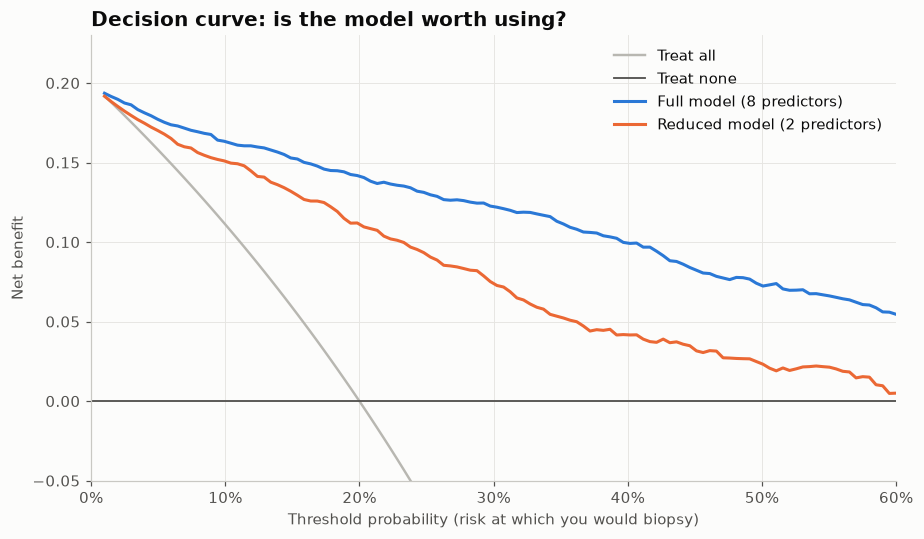

In [3]:
def net_benefit(y, p, thresholds):
    n = len(y)
    out = []
    for pt in thresholds:
        treat = p >= pt
        tp = (treat & (y == 1)).sum() / n
        fp = (treat & (y == 0)).sum() / n
        out.append(tp - fp * pt / (1 - pt))
    return np.array(out)

th = np.linspace(0.01, 0.6, 120)
prev = y_te.mean()
nb_all = prev - (1 - prev) * th / (1 - th)
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot(th, nb_all, color=GRAY, linewidth=1.6, label="Treat all")
ax.axhline(0, color="#52514e", linewidth=1.2, label="Treat none")
ax.plot(th, net_benefit(y_te, p_full, th), color=PALETTE[0], label="Full model (8 predictors)")
ax.plot(th, net_benefit(y_te, p_reduced, th), color=PALETTE[1], label="Reduced model (2 predictors)")
ax.set_ylim(-0.05, prev + 0.03)
ax.set_xlim(0, 0.6)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_xlabel("Threshold probability (risk at which you would biopsy)")
ax.set_ylabel("Net benefit")
ax.set_title("Decision curve: is the model worth using?")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

## How to read it

At any threshold, the strategy with the highest line gives the most benefit. The full model gives the highest net benefit across almost the whole range. The reduced model is useful too but falls towards zero at high thresholds. Treating everyone is only competitive at very low thresholds.

## Reference

This method comes from the research literature:

- Vickers, A. J. & Elkin, E. B. (2006). Decision curve analysis: a novel method for evaluating prediction models. Medical Decision Making 26(6), 565–574. <https://doi.org/10.1177/0272989X06295361>

---
Standalone script: [`decision_curve.py`](decision_curve.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)